# Задача данного notebook проанализировать какие есть выбросы, где они находиться и как избавиться от них.

### Данный notebook должен выдать notebook должен выдать csv, где в данных мы уверены, что нету какого-то ужасного ужаса

### Загрузка данных

In [1]:
import pandas as pd
from datetime import datetime
from datetime import timedelta

def time_delta(closed_at, published_at):
    if pd.isna(closed_at) or pd.isna(published_at):
        return pd.NaT

    closed = datetime.fromisoformat(str(closed_at))
    published = datetime.fromisoformat(str(published_at))
    return closed - published

df = pd.read_csv("data/listings.csv")
df = df.sort_values("listing_id", ascending=True)
display(df.shape)
df.head()

(15457, 18)

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
14697,100004,10001,private,NaN,Велосипед горный с документами,3200,2800,3,289.0,Moscow,2026-08-01 07:07:09,2026-08-31 07:07:09,истёк срок,298,8,2,12,35
10109,100009,10005,private,Детские товары,Самокат детский как новый,3950,3950,6,100.0,Moscow,2026-08-01 08:06:10,2026-08-11 13:23:30,снято продавцом,237,8,1,12,66
12896,100012,10011,private,Детские товары,Манеж,2050,2050,6,107.0,Казань,2026-08-01 08:13:44,2026-08-05 20:27:25,снято продавцом,23,1,0,1,9
3356,100013,10012,private,Бытовая техника,Холодильник Bosch в хорошем состоянии,12680,12680,8,84.0,Москва,2026-08-01 08:24:58,2026-08-05 14:14:26,снято продавцом,32,1,0,2,18
12498,100018,10013,private,Мебель и интерьер,Стеллаж как новый,12990,12990,6,173.0,Москва,2026-08-01 08:29:46,2026-08-03 08:46:37,снято продавцом,0,0,0,0,0


### Убираем строчки, где время _published_at_ > _closed_at_

In [2]:
delta = pd.Series(
    [
        time_delta(closed, published)
        for closed, published in zip(df["closed_at"], df["published_at"])
    ],
    index=df.index,
    name="delta",
    dtype="timedelta64[ns]",
)

df["delta"] = delta
listing_ids_of_bad_time = df.loc[~(df["delta"] > timedelta(0)), "listing_id"].to_list()
df = df[df["delta"] > timedelta(0)]
df = df.drop("delta", axis=1)
display(df.shape)

(15417, 18)

### Посторим графики и посмотрим на данные. Цель - понять, где есть впринципе выбросы и где есть cлишком больших выбросы

##### Смотрим по этим столбцам: 
* price 
* current_price
* photos_count
* description_length
* views_total
* favorites_total
* phone_views_total
* chats_total
* messages_total

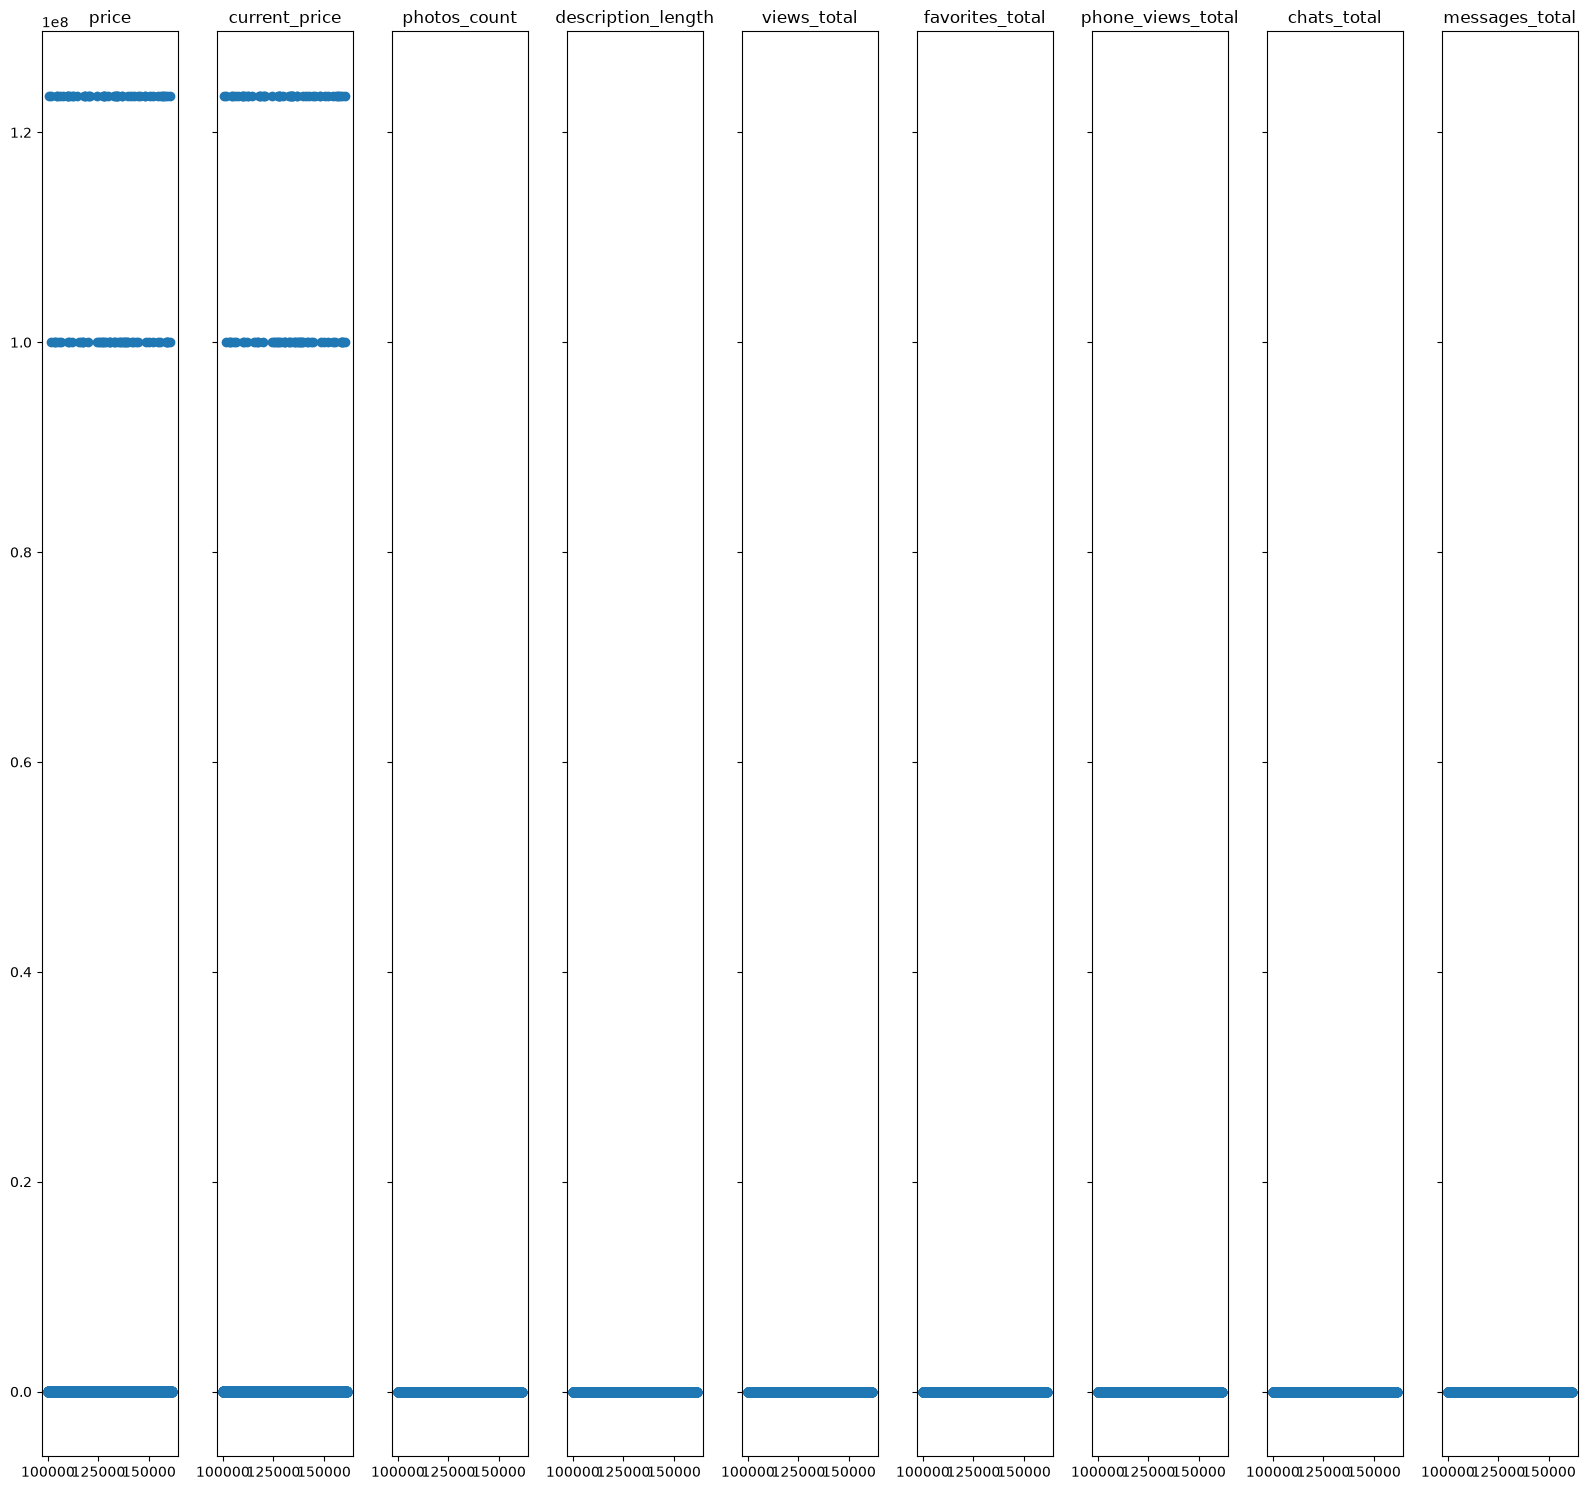

In [3]:
import matplotlib.pyplot as plt

values = ["price", "current_price", "photos_count", "description_length", "views_total", "favorites_total", "phone_views_total", "chats_total", "messages_total"]

fig, axes = plt.subplots(
    1, len(values), figsize=(16, 15), sharey=True, squeeze=False
)


for ax, value in zip(axes[0], values):
    y = df[value]

    ax.scatter(df["listing_id"], y)
    ax.set_title(f"{value}")

fig.tight_layout()
plt.show()

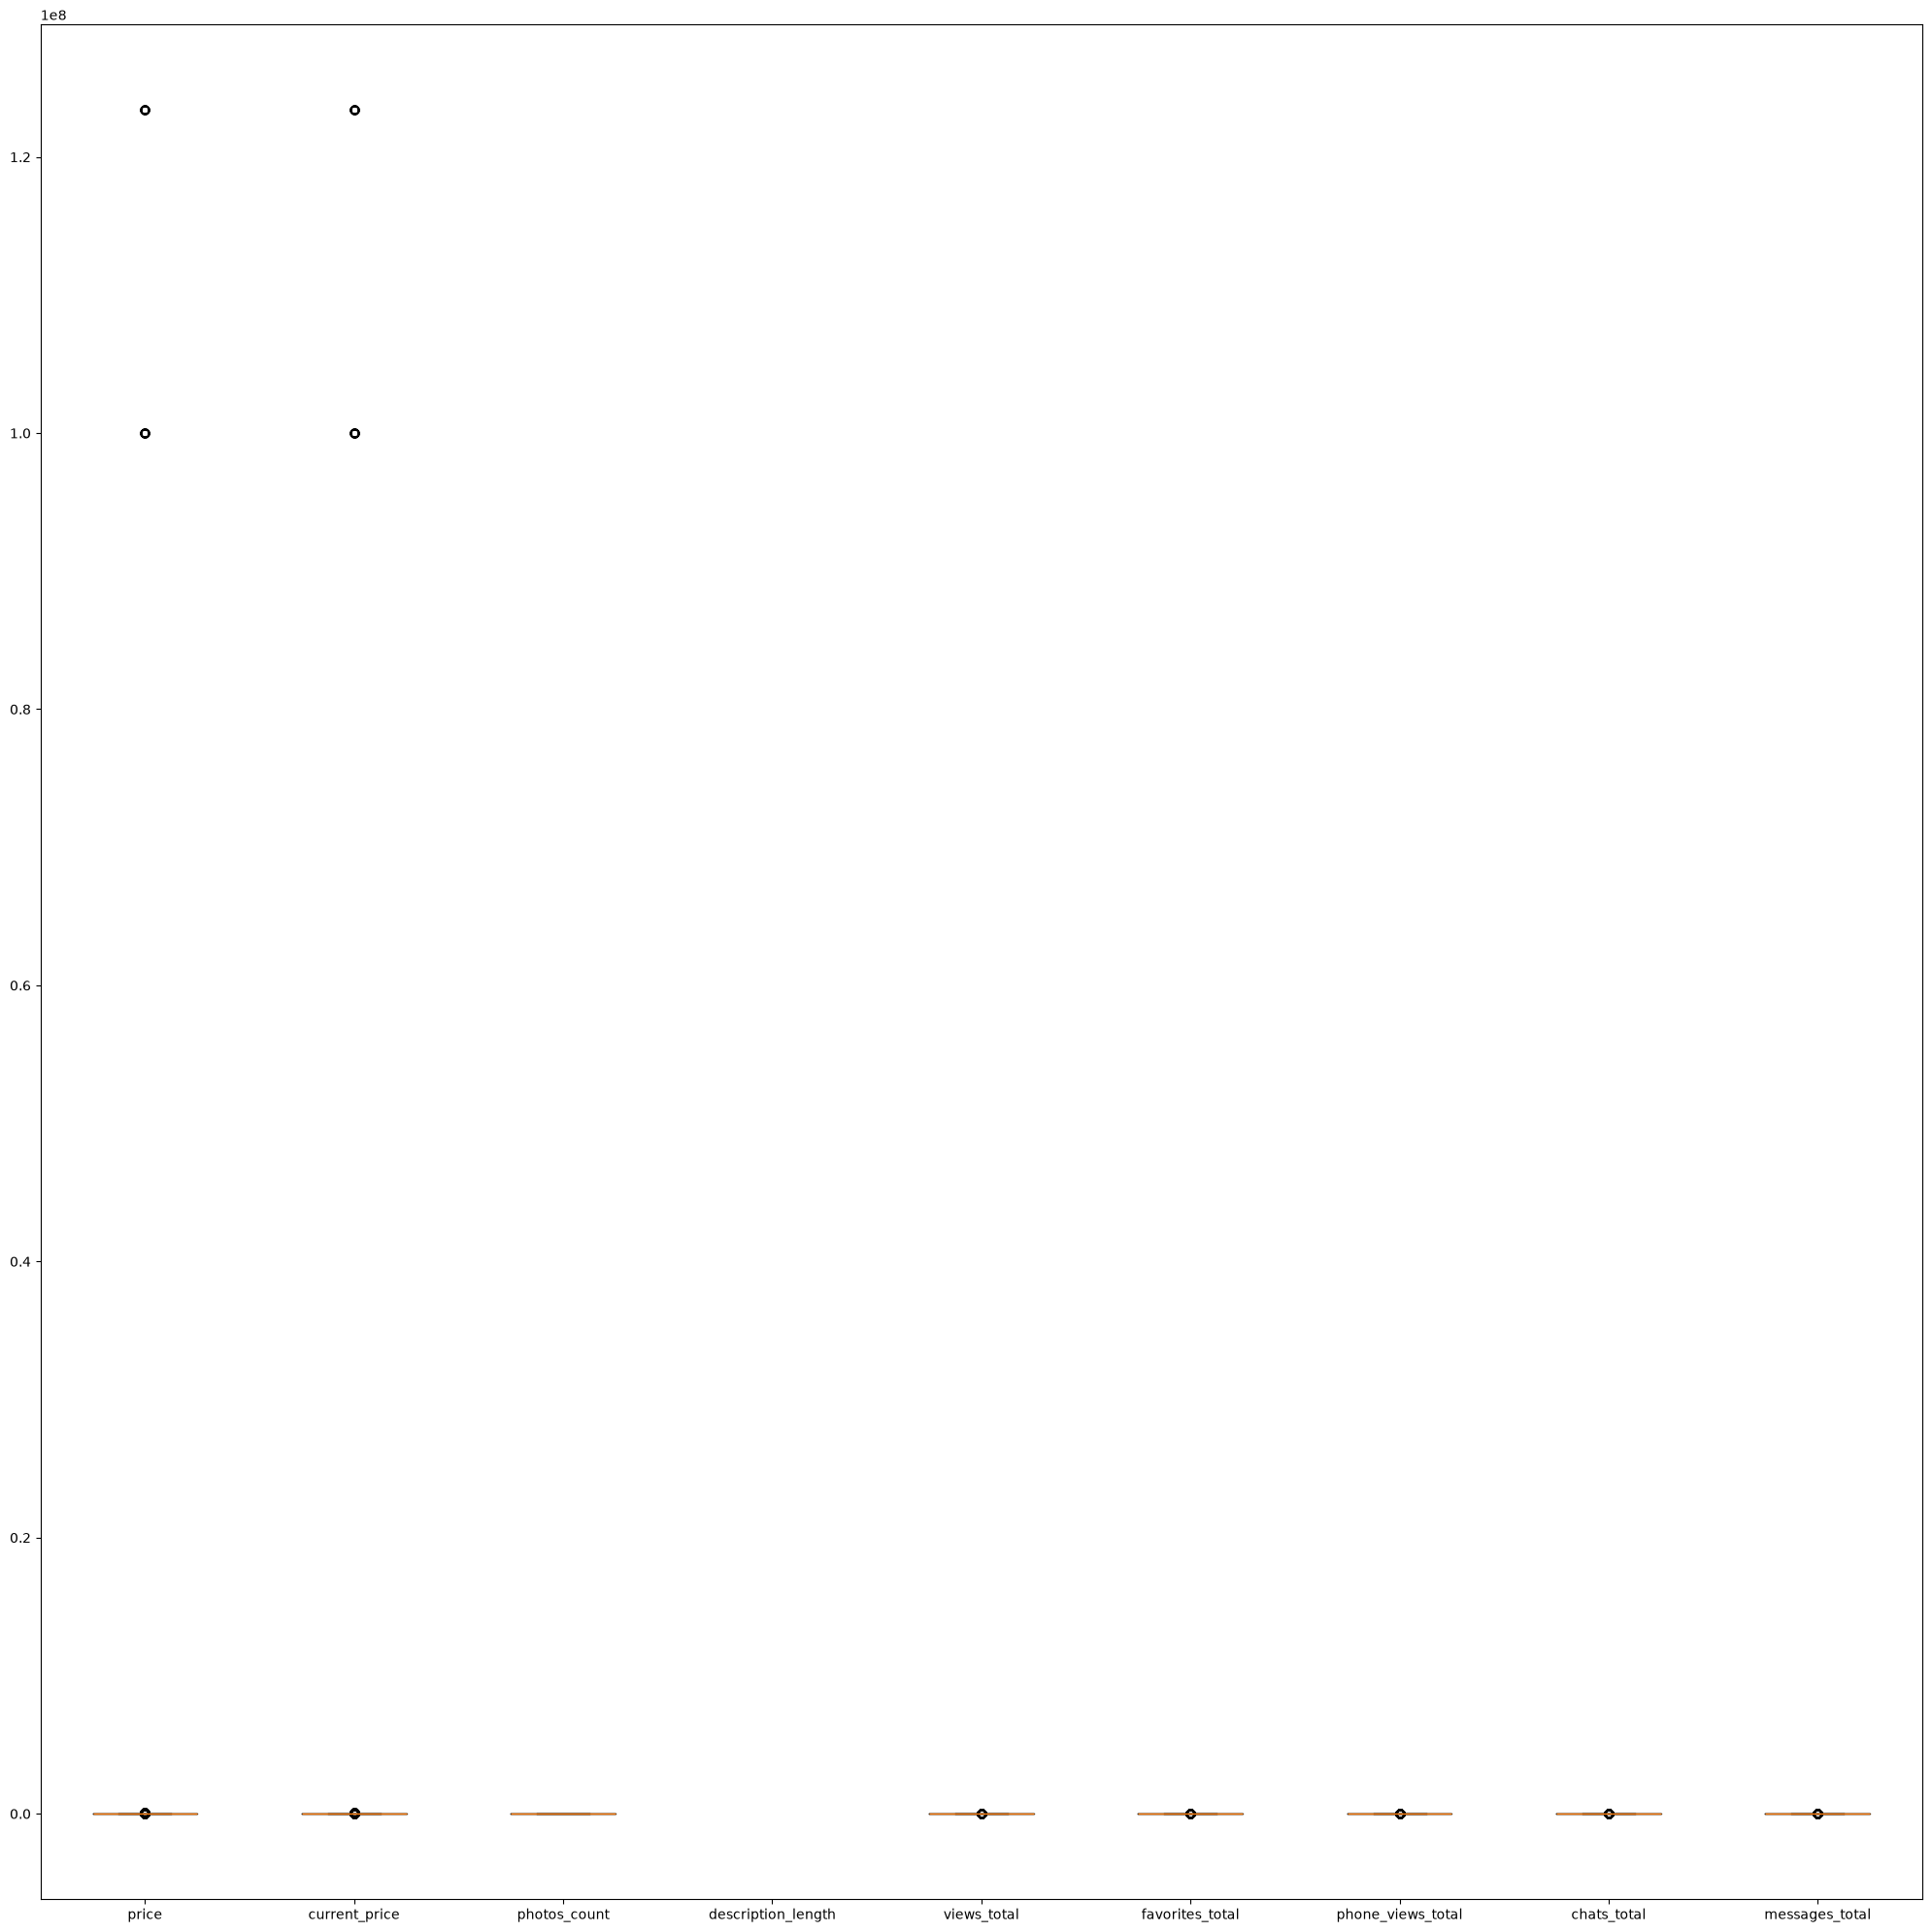

In [4]:
values = ["price", "current_price", "photos_count", "description_length", "views_total", "favorites_total", "phone_views_total", "chats_total", "messages_total"]
    
data = [
    df[value]
    for value in values
]

plt.figure(figsize=(20, 20))
plt.boxplot(data, tick_labels=values)

plt.tight_layout()
plt.show()

### Формируем отдельную csv, со слишком большими выбросами

In [5]:
df_vibros = df[(df["price"] > 0.2*10**8) | (df["current_price"] > 0.2*10**8)]
display(df_vibros.shape)
#df_vibros.to_csv("vibros.csv", index=False, encoding="utf-8")
df_vibros

(99, 18)

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
2978,100352,10374,private,Одежда и обувь,Рюкзак городской в хорошем состоянии,123456789,123456789,5,66.0,Новосибирск,2026-08-01 17:40:25,2026-08-06 18:03:07,снято продавцом,55,3,0,1,14
8015,101374,11376,business,Спорт и отдых,Беговая дорожка отличное состояние,123456789,123456789,5,768.0,Санкт-Петербург,2026-08-02 18:30:31,2026-09-01 18:30:31,истёк срок,238,6,0,15,53
5608,101453,11471,private,Электроника,Наушники беспроводные новый,99999999,99999999,5,50.0,Новосибирск,2026-08-02 19:47:31,2026-08-05 17:57:12,снято продавцом,35,1,0,2,23
9551,102833,12850,private,Спорт и отдых,Гантели разборные отличное состояние,99999999,99999999,6,50.0,Санкт-Петербург,2026-08-04 18:20:36,2026-08-08 23:07:37,снято продавцом,36,2,1,0,0
13249,103662,11693,private,Одежда и обувь,Куртка зимняя в хорошем состоянии,99999999,99999999,6,138.0,Москва,2026-08-05 17:59:10,2026-08-06 21:03:57,снято продавцом,25,1,0,2,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1664,158937,32792,private,Бытовая техника,Холодильник Bosch в хорошем состоянии,123456789,123456789,3,53.0,Москва,2026-10-03 23:48:34,2026-10-06 08:18:40,снято продавцом,34,1,0,2,4
3555,159062,40694,private,Спорт и отдых,Беговая дорожка торг,99999999,99999999,3,169.0,Москва,2026-10-04 10:42:05,2026-10-05 19:37:49,снято продавцом,11,0,0,1,8
14069,159591,18365,business,Одежда и обувь,Пальто шерстяное новый,99999999,99999999,7,765.0,Казань,2026-10-04 17:53:52,2026-11-03 17:53:52,истёк срок,248,10,2,10,50
9171,160202,28310,private,Одежда и обувь,Рюкзак городской,99999999,99999999,2,103.0,екатеринбург,2026-10-05 10:16:43,2026-10-11 13:38:14,снято продавцом,60,2,1,2,19


### Чистим основной df

In [6]:
indexes_high = df_vibros["listing_id"]
display(df.shape)
df = df[~df["listing_id"].isin(indexes_high)]
display(df.shape)

(15417, 18)

(15318, 18)

## Смотрим на распределение данных уже без слишком больших выбросов и посмотрим какие есть слишком маленькие данные(где priсe очень низкий)

In [7]:
med_price = df["price"].median()
med_price_curr = df["current_price"].median()

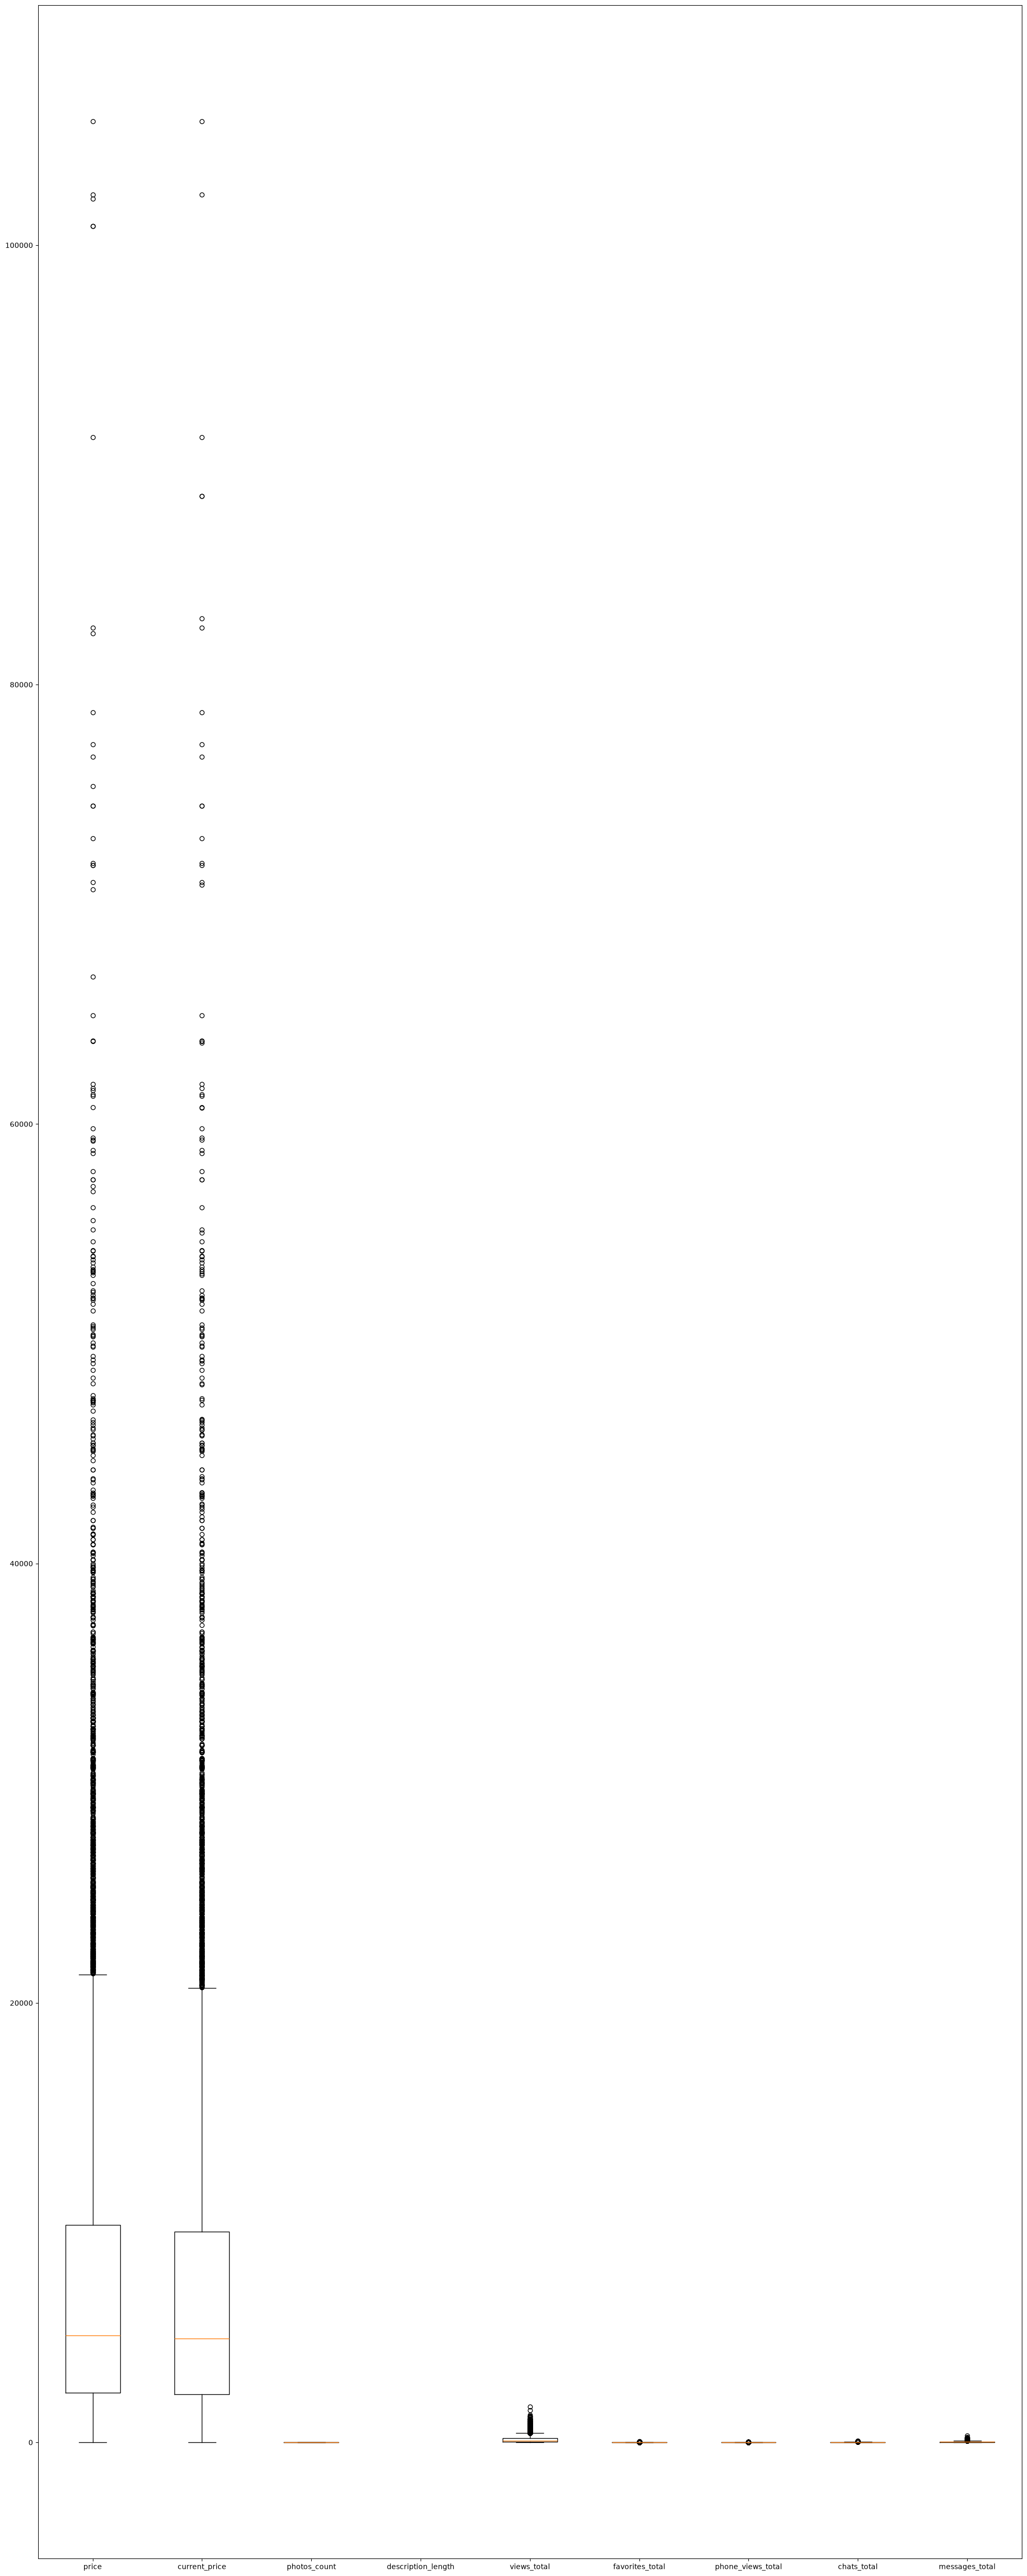

In [8]:
import matplotlib.ticker as ticker

values = ["price", "current_price", "photos_count", "description_length", "views_total", "favorites_total", "phone_views_total", "chats_total", "messages_total"]
    
data = [
    df[value]
    for value in values
]

plt.figure(figsize=(20, 50))
plt.boxplot(data, tick_labels=values)

ax.grid(True)
plt.tight_layout()
plt.show()

In [9]:
df_low_med = df[(df["price"] < med_price) | (df["current_price"] < med_price_curr)]
df_low_med_price = df_low_med.sort_values(by="price", ascending=True)
df_low_med_price_curr = df_low_med.sort_values(by="current_price", ascending=True)

In [10]:
df_low_med_price.head(30)

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
2361,160547,38181,private,Электроника,Ноутбук Lenovo IdeaPad б/у,0,0,8,182.0,Москва,2026-10-05 15:47:49,2026-10-15 13:35:39,снято продавцом,251,10,3,5,31
4028,133837,24087,private,Одежда и обувь,Рюкзак городской новый,0,0,4,73.0,Москва,2026-09-09 19:08:03,2026-10-09 19:08:03,истёк срок,244,10,2,11,47
4338,134076,32714,private,Мебель и интерьер,Стеллаж в хорошем состоянии,0,0,8,77.0,Санкт-Петербург,2026-09-09 22:21:10,2026-10-09 22:21:10,истёк срок,130,6,4,6,21
7101,138924,16221,private,NaN,Сапоги зимние новый,0,0,0,67.0,Санкт-Петербург,2026-09-14 16:48:14,2026-09-16 21:07:20,снято продавцом,14,0,0,1,2
1522,124381,24976,private,Одежда и обувь,Платье вечернее,0,0,4,33.0,Самара,2026-08-30 18:38:54,2026-09-11 11:38:57,снято продавцом,115,5,1,3,7
2622,105954,15583,business,Одежда и обувь,Кроссовки Nike,0,0,9,383.0,Москва,2026-08-08 17:21:23,2026-09-07 17:21:23,истёк срок,523,17,0,25,91
8325,155518,27412,private,Запчасти и аксессуары,Бампер передний срочно,0,0,10,254.0,Москва,2026-09-30 21:07:05,2026-10-15 18:35:49,снято продавцом,245,8,6,4,24
2909,156112,36750,private,Запчасти и аксессуары,Бампер передний,0,0,3,26.0,Москва,2026-10-01 15:42:17,2026-10-09 08:06:38,снято продавцом,26,0,1,2,14
1962,128375,20645,private,Электроника,Наушники беспроводные торг,0,0,1,177.0,Moscow,2026-09-03 22:58:21,2026-10-03 22:58:21,истёк срок,392,7,3,16,51
7577,124945,28572,private,Бытовая техника,Кондиционер отличное состояние,0,0,4,135.0,Санкт-Петербург,2026-08-31 14:10:40,2026-09-11 20:33:19,снято продавцом,77,1,1,4,25


In [11]:
df_low_med_price_curr.head(30)

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
8335,111237,16005,private,Детские товары,Кроватка детская,0,0,3,238.0,Казань,2026-08-14 19:18:20,2026-08-21 20:03:50,снято продавцом,47,1,1,4,23
10879,115114,22460,private,Детские товары,Стульчик для кормления в хорошем состоянии,0,0,4,118.0,Москва,2026-08-19 10:38:47,2026-08-23 19:37:05,снято продавцом,84,2,1,5,28
7101,138924,16221,private,NaN,Сапоги зимние новый,0,0,0,67.0,Санкт-Петербург,2026-09-14 16:48:14,2026-09-16 21:07:20,снято продавцом,14,0,0,1,2
12333,144507,25668,private,Бытовая техника,Холодильник Bosch как новый,0,0,6,174.0,Нижний Новгород,2026-09-19 22:00:59,2026-10-01 11:41:28,снято продавцом,93,2,2,3,18
8419,111282,12165,private,Бытовая техника,Кондиционер,0,0,4,NaN,Москва,2026-08-14 20:05:07,2026-08-25 21:56:23,снято продавцом,82,3,1,2,25
1085,141488,32184,private,Бытовая техника,Посудомоечная машина с документами,0,0,7,113.0,Самара,2026-09-16 20:54:32,2026-09-18 22:07:42,снято продавцом,20,0,0,2,4
8325,155518,27412,private,Запчасти и аксессуары,Бампер передний срочно,0,0,10,254.0,Москва,2026-09-30 21:07:05,2026-10-15 18:35:49,снято продавцом,245,8,6,4,24
12040,106726,16297,private,Одежда и обувь,Кроссовки Nike новый,0,0,2,43.0,Москва,2026-08-09 16:12:49,2026-09-08 16:12:49,истёк срок,289,10,0,16,56
229,141488,32184,private,Бытовая техника,Посудомоечная машина с документами,0,0,7,113.0,Самара,2026-09-16 20:54:32,2026-09-18 22:07:42,снято продавцом,20,0,0,2,4
15405,110579,14546,private,Спорт и отдых,Спальный мешок в хорошем состоянии,0,0,3,NaN,Нижний Новгород,2026-08-13 22:32:47,2026-08-22 17:13:33,снято продавцом,34,2,0,1,7


In [12]:
df_low = df[(df["price"] < 20) | (df["current_price"] < 20)]
display(df_low.shape)
df_low = df_low.sort_values(by="price", ascending=False)
low_listing_ids = df_low["listing_id"]

(86, 18)

### Убираем слишком низкие значения из df, т.е. где price = 0 или 1

In [13]:
display(df.shape)
df = df[~df["listing_id"].isin(low_listing_ids)]
df

(15318, 18)

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
14697,100004,10001,private,NaN,Велосипед горный с документами,3200,2800,3,289.0,Moscow,2026-08-01 07:07:09,2026-08-31 07:07:09,истёк срок,298,8,2,12,35
10109,100009,10005,private,Детские товары,Самокат детский как новый,3950,3950,6,100.0,Moscow,2026-08-01 08:06:10,2026-08-11 13:23:30,снято продавцом,237,8,1,12,66
12896,100012,10011,private,Детские товары,Манеж,2050,2050,6,107.0,Казань,2026-08-01 08:13:44,2026-08-05 20:27:25,снято продавцом,23,1,0,1,9
3356,100013,10012,private,Бытовая техника,Холодильник Bosch в хорошем состоянии,12680,12680,8,84.0,Москва,2026-08-01 08:24:58,2026-08-05 14:14:26,снято продавцом,32,1,0,2,18
12498,100018,10013,private,Мебель и интерьер,Стеллаж как новый,12990,12990,6,173.0,Москва,2026-08-01 08:29:46,2026-08-03 08:46:37,снято продавцом,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5268,161253,22519,business,Одежда и обувь,Пальто шерстяное,1410,1410,6,302.0,Краснодар,2026-10-05 23:39:28,2026-11-04 23:39:28,истёк срок,415,9,1,22,70
8729,161260,13284,private,Одежда и обувь,Костюм мужской,450,410,5,50.0,Екатеринбург,2026-10-05 23:39:59,2026-10-18 22:05:24,снято продавцом,254,5,4,6,19
13486,161261,23053,private,Детские товары,Конструктор LEGO новый,1250,1250,3,94.0,Казань,2026-10-05 23:48:53,2026-10-10 16:32:37,снято продавцом,23,0,1,1,4
14691,161265,25846,private,Бытовая техника,Кофемашина DeLonghi,4530,4530,4,403.0,Москва,2026-10-05 23:56:37,2026-10-12 13:04:41,снято продавцом,28,1,0,1,9


### Ура. У нас очищенный df

In [14]:
df.to_csv("listins_without_anomailes.csv", index=False, encoding="utf-8")

### Проверка этого df

In [15]:
df_testing = pd.read_csv("listins_without_anomailes.csv")

In [16]:
df_testing = df_testing.sort_values("listing_id", ascending=True)

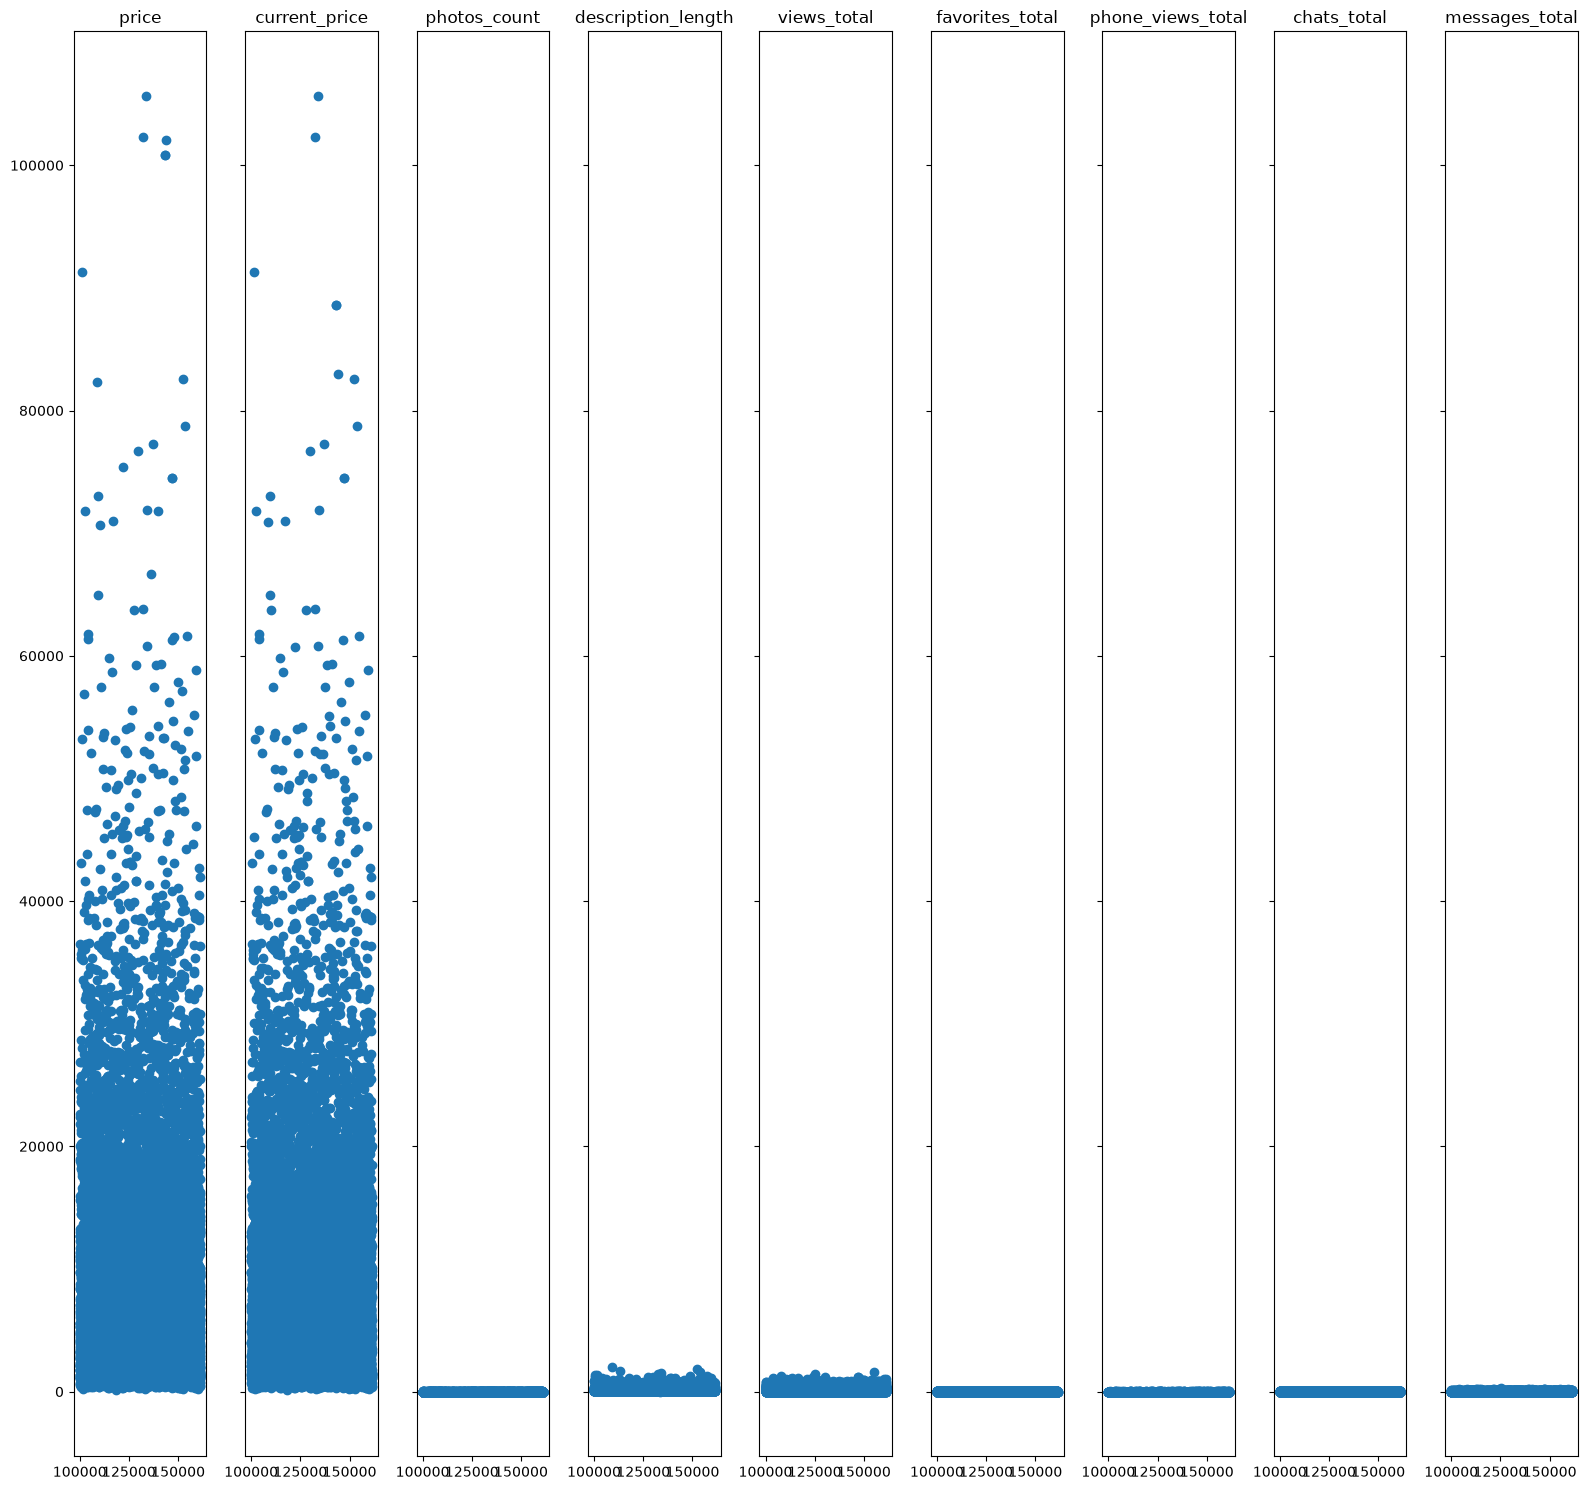

In [17]:
values = ["price", "current_price", "photos_count", "description_length", "views_total", "favorites_total", "phone_views_total", "chats_total", "messages_total"]

fig, axes = plt.subplots(
    1, len(values), figsize=(16, 15), sharey=True, squeeze=False
)


for ax, value in zip(axes[0], values):
    y = df[value]

    ax.scatter(df["listing_id"], y)
    ax.set_title(f"{value}")

fig.tight_layout()
plt.show()

### Убираем строчки из всех csvшек, где выбросы по супер большим и по супер малым выбросам, выбросы по времени. Получаем красивые CSV

In [18]:
files = ["events.csv", "listings.csv", "messages.csv", "surveys.csv"]
for file in files:
    df = pd.read_csv(f"data/{file}")
    display(df.shape)
    t = df.shape[0]
    df = df[~df["listing_id"].isin(listing_ids_of_bad_time)]
    df = df[~df["listing_id"].isin(low_listing_ids)]
    df = df[~df["listing_id"].isin(indexes_high)]
    display(df.shape)
    display(t - df.shape[0])
    display("--------------------------------------------")
    df.to_csv(f"data/data_wthout_anomailes/{file[:-4]}_wthout_anomailes.csv", index=False, encoding="utf-8")

(183242, 5)

(180523, 5)

2719

'--------------------------------------------'

(15457, 18)

(15232, 18)

... (6 outputs left out)

(6061, 4)

(5963, 4)

98

'--------------------------------------------'

In [19]:
files = ["events.csv", "listings.csv", "messages.csv", "surveys.csv"]
for file in files:
    df = pd.read_csv(f"data/{file}")
    display(df.shape)
    t = df.shape[0]
    df = pd.DataFrame()
    df = df[df["listing_id"].isin(listing_ids_of_bad_time)]
    df = df[df["listing_id"].isin(low_listing_ids)]
    df = df[df["listing_id"].isin(indexes_high)]
    display(df.shape)
    display(t - df.shape[0])
    display("--------------------------------------------")
    df.to_csv(f"data/data_ONLY_anomailes/{file[:-4]}_ONLY_anomailescsv", index=False, encoding="utf-8")

(183242, 5)

KeyError: 'listing_id'